# **KLASIFIKASI POTENSI PANEL SURYA MENGGUNAKAN EFFICIENTNET-B0**


## **Mount Google Drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Menginstal package**

In [ ]:
!pip install torch torchvision torchaudio --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 108.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 75.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.5/59.5 MB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.9/

In [ ]:
!pip install -U tensorboard setuptools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 18.6 MB/s eta 0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 80.10.2
    Uninstalling setuptools-80.10.2:
      Successfully uninstalled setuptools-80.10.2
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
  Attempting uninstall: tensorboard
    Found existing installation: tensorboard 2.20.0
    Uninstalling tensorboard-2.20.0:
      Successfully uninstalled tensorboard-2.20.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
google-ai-gene

## **Mengimpor package**

In [ ]:
import os
import time
import copy
import numpy as np
from matplotlib import pyplot as plt
import itertools
import multiprocessing
from PIL import Image

import torch
import torchvision
from torchvision import datasets, models, transforms
import torch.utils.data as data
from torch.utils.tensorboard import SummaryWriter
import shutil
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torchsummary import summary
import torch.nn.functional as F

## **Set environment variabel**

In [ ]:
os.environ['CUDA_LAUNCH_BLOCKING'] = "1"

## **Menentukan direktori dataset**

In [ ]:
# Path ke direktori train, validasi, dan test
train_dir = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/train'
val_dir   = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/val'
test_dir  = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test'

## **Membuat variabel awal untuk percobaan**

In [ ]:
# Jumlah epoch
num_epochs = 50

# Batch size
batch_size = 32

# Jumlah Kelas
num_classes = 2

# Jumlah CPU untuk pemuatan data
num_cpu = multiprocessing.cpu_count()

print(f"Jumlah CPU yang digunakan: {num_cpu}")

Jumlah CPU yang digunakan: 2


## **Normalisasi Menggunakan Statistik ImageNet**


In [ ]:
mean = torch.tensor([0.485, 0.456, 0.406])
std  = torch.tensor([0.229, 0.224, 0.225])

print(f'Mean ImageNet: {mean}')
print(f'Std ImageNet : {std}')

Mean ImageNet: tensor([0.4850, 0.4560, 0.4060])
Std ImageNet : tensor([0.2290, 0.2240, 0.2250])


## **Visualisasi Efek Normalisasi**

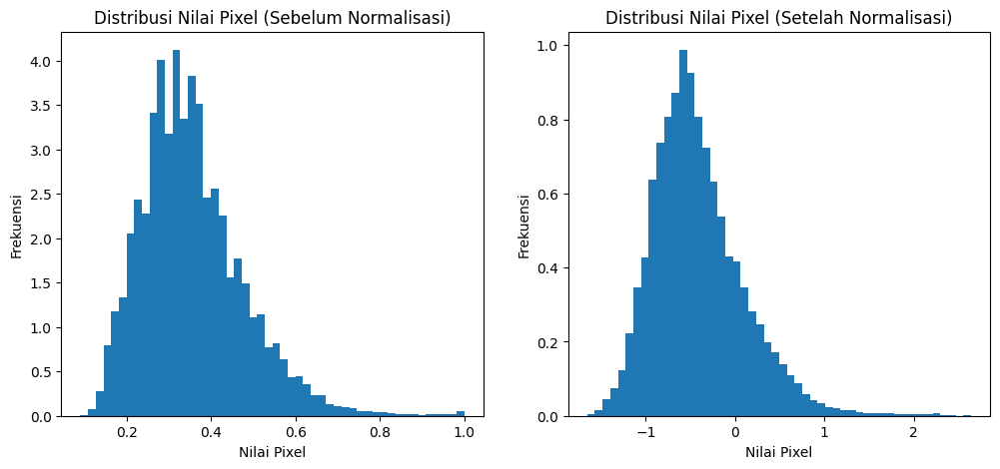

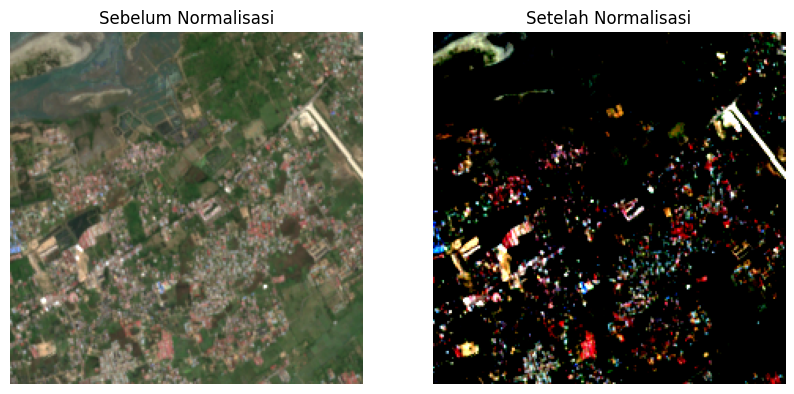

In [ ]:
# Ambil satu gambar contoh dari folder train (kelas Potential) untuk
# ditampilkan sebelum & sesudah normalisasi
folder_contoh = os.path.join(train_dir, 'Potential')
nama_file_contoh = sorted(os.listdir(folder_contoh))[0]
sample_img_path = os.path.join(folder_contoh, nama_file_contoh)

transform_tanpa_norm = transforms.Compose([transforms.ToTensor()])
transform_dengan_norm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

img = Image.open(sample_img_path)
img_tensor = transform_tanpa_norm(img)
img_normalized = transform_dengan_norm(img)

img_np = img_tensor.permute(1, 2, 0).numpy()
img_np_norm = img_normalized.permute(1, 2, 0).numpy()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(img_np.ravel(), bins=50, density=True)
plt.xlabel("Nilai Pixel")
plt.ylabel("Frekuensi")
plt.title("Distribusi Nilai Pixel (Sebelum Normalisasi)")

plt.subplot(1, 2, 2)
plt.hist(img_np_norm.ravel(), bins=50, density=True)
plt.xlabel("Nilai Pixel")
plt.ylabel("Frekuensi")
plt.title("Distribusi Nilai Pixel (Setelah Normalisasi)")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_np)
axes[0].set_title("Sebelum Normalisasi")
axes[0].axis("off")

axes[1].imshow(np.clip(img_np_norm, 0, 1))
axes[1].set_title("Setelah Normalisasi")
axes[1].axis("off")
plt.show()

## **Membuat Transformasi Data untuk Dataset**

In [ ]:
image_transforms = {
    'train': transforms.Compose([
        transforms.RandomHorizontalFlip(),
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ]),
}


## **Ringkasan dan Visualisasi Dataset**

In [ ]:
dataset = {
    'train': datasets.ImageFolder(root=train_dir, transform=image_transforms['train']),
    'val': datasets.ImageFolder(root=val_dir, transform=image_transforms['val']),
    'test': datasets.ImageFolder(root=test_dir, transform=image_transforms['test']),
}

In [ ]:
classes = dataset['train'].classes
print(f"Banyak kelas pada dataset: {len(classes)}")
print(f"Kelas pada dataset: {classes}")

Banyak kelas pada dataset: 2
Kelas pada dataset: ['Not_Potential', 'Potential']


In [ ]:
dataset_sizes = {x: len(dataset[x]) for x in ['train', 'val', 'test']}
print(f"Banyak data gambar pada data latih   : {dataset_sizes['train']}")
print(f"Banyak data gambar pada data validasi: {dataset_sizes['val']}")
print(f"Banyak data gambar pada data uji     : {dataset_sizes['test']}")

Banyak data gambar pada data latih   : 3820
Banyak data gambar pada data validasi: 906
Banyak data gambar pada data uji     : 449


In [ ]:
# Drop_last=True HANYA dipakai untuk train (supaya ukuran batch
# konsisten selama training). Untuk val/test pakai drop_last=False
# supaya SELURUH data validasi/uji ikut dievaluasi, tidak ada yang
# terbuang di akhir setiap epoch. shuffle juga dimatikan untuk val/test
# karena tidak ada gunanya diacak untuk evaluasi.
dataloaders = {
    'train': data.DataLoader(dataset['train'], batch_size=batch_size, shuffle=True,
                              num_workers=num_cpu, pin_memory=True, drop_last=True),
    'val':   data.DataLoader(dataset['val'], batch_size=batch_size, shuffle=False,
                              num_workers=num_cpu, pin_memory=True, drop_last=False),
    'test':  data.DataLoader(dataset['test'], batch_size=batch_size, shuffle=False,
                              num_workers=num_cpu, pin_memory=True, drop_last=False),
}

num_batches = {x: len(dataloaders[x]) for x in ['train', 'val', 'test']}
print(f"Banyak batch untuk data latih   : {num_batches['train']}")
print(f"Banyak batch untuk data validasi: {num_batches['val']}")
print(f"Banyak batch untuk data uji     : {num_batches['test']}")

Banyak batch untuk data latih   : 119
Banyak batch untuk data validasi: 29
Banyak batch untuk data uji     : 15


In [ ]:
images, labels = next(iter(dataloaders['train']))
print(f"Jumlah batch size adalah: {images.shape[0]}")
print(f"Dimensi ukuran gambar adalah: {images.shape}")

Jumlah batch size adalah: 32
Dimensi ukuran gambar adalah: torch.Size([32, 3, 224, 224])


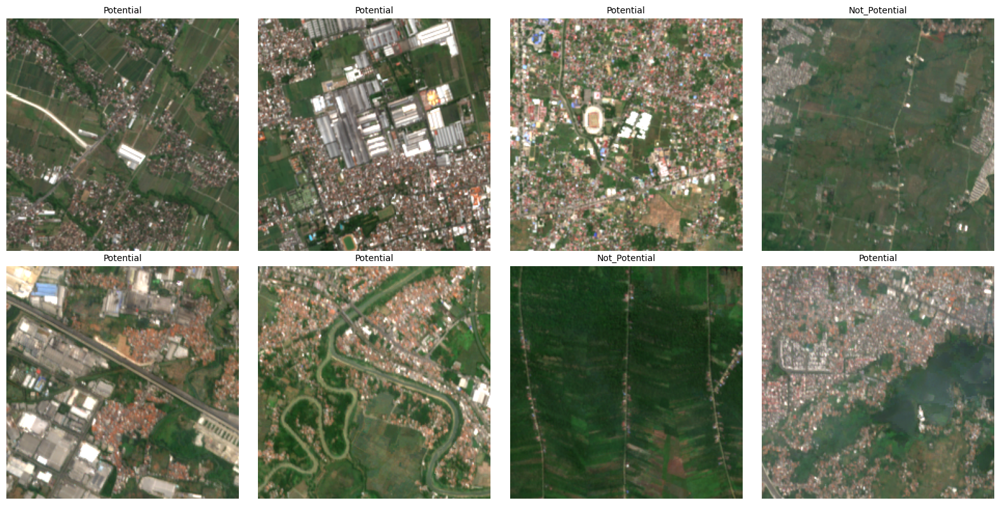

In [ ]:
def imshow_single(ax, img_tensor, title=None):
    """Menampilkan satu gambar (dengan invers normalisasi ImageNet)
    ke sebuah subplot tertentu, supaya tiap gambar bisa punya judul
    sendiri-sendiri yang jelas."""
    img = img_tensor.numpy().transpose((1, 2, 0))
    img = (img * std.numpy()) + mean.numpy()
    img = np.clip(img, 0, 1)

    ax.imshow(img)
    if title is not None:
        ax.set_title(title, fontsize=10)
    ax.axis('off')


inputs, classes_batch = next(iter(dataloaders['train']))
class_names = dataset['train'].classes

JUMLAH_DITAMPILKAN = 8

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx, ax in enumerate(axes.flat):
    if idx >= JUMLAH_DITAMPILKAN:
        ax.axis('off')
        continue
    imshow_single(ax, inputs[idx], title=class_names[classes_batch[idx]])

plt.tight_layout()
plt.show()

## **Device Default**

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f'Menggunakan perangkat: {device}')

Menggunakan perangkat: cuda:0


In [ ]:
images, labels = images.to(device), labels.to(device)

## **Melatih Model EfficientNet-B0 (Model Utama)**


In [ ]:
print("\nMemuat EfficientNet-B0 \n")

# Load EfficientNet-B0
weights = models.EfficientNet_B0_Weights.DEFAULT
model_ft = models.efficientnet_b0(weights=weights)


# classifier
# classifier[0] = Dropout
# classifier[1] = Linear

model_ft.classifier[0].p = 0.5

num_ftrs = model_ft.classifier[1].in_features

model_ft.classifier[1] = nn.Linear(
    num_ftrs,
    num_classes
)

model_ft = model_ft.to(device)

# FULL FINE-TUNING

for param in model_ft.parameters():
    param.requires_grad = True

# Cek jumlah parameter yang dilatih
trainable = sum(
    p.numel()
    for p in model_ft.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model_ft.parameters()
)

print(
    f"Parameter yang dilatih : {trainable:,} "
    f"dari total {total_params:,} "
    f"({trainable/total_params:.1%})"
)


# Loss

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)


# Optimizer

optimizer_ft = optim.AdamW(
    model_ft.parameters(),
    lr=1e-5,
    weight_decay=1e-3
)


# Scheduler
# Warmup 3 epoch -> Cosine Annealing

warmup_epochs = 3

warmup_scheduler = lr_scheduler.LinearLR(
    optimizer_ft,
    start_factor=0.1,
    total_iters=warmup_epochs
)

cosine_scheduler = lr_scheduler.CosineAnnealingLR(
    optimizer_ft,
    T_max=num_epochs - warmup_epochs,
    eta_min=1e-6
)

exp_lr_scheduler = lr_scheduler.SequentialLR(
    optimizer_ft,
    schedulers=[
        warmup_scheduler,
        cosine_scheduler
    ],
    milestones=[warmup_epochs]
)


Memuat EfficientNet-B0 

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 85.3MB/s]


Parameter yang dilatih : 4,010,110 dari total 4,010,110 (100.0%)


In [ ]:
print('Model Summary:-\n')
summary(model_ft, input_size=(3, 224, 224))
print(model_ft)

Model Summary:-

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 112, 112]             864
       BatchNorm2d-2         [-1, 32, 112, 112]              64
              SiLU-3         [-1, 32, 112, 112]               0
            Conv2d-4         [-1, 32, 112, 112]             288
       BatchNorm2d-5         [-1, 32, 112, 112]              64
              SiLU-6         [-1, 32, 112, 112]               0
 AdaptiveAvgPool2d-7             [-1, 32, 1, 1]               0
            Conv2d-8              [-1, 8, 1, 1]             264
              SiLU-9              [-1, 8, 1, 1]               0
           Conv2d-10             [-1, 32, 1, 1]             288
          Sigmoid-11             [-1, 32, 1, 1]               0
SqueezeExcitation-12         [-1, 32, 112, 112]               0
           Conv2d-13         [-1, 16, 112, 112]             512
      BatchNorm2d-14  

In [ ]:
writer = SummaryWriter('/content/content/runs/summary_1_effnetb0')
writer.add_graph(model_ft, images)

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## **Fungsi Menyimpan Checkpoint**

In [ ]:
def save_checkpoint(state, is_best, filename='checkpoint_effnetb0.pth.tar',
                     best_filename='model_best_EfficientNetB0.pth.tar',
                     labels_filename='labels.txt'):
    """Menyimpan checkpoint model, serta model terbaik jika berlaku"""
    if not os.path.exists('model_checkpoints_effnetb0'):
        os.mkdir('model_checkpoints_effnetb0')

    filename = os.path.join('model_checkpoints_effnetb0', filename)
    best_filename = os.path.join('model_checkpoints_effnetb0', best_filename)
    labels_filename = os.path.join('model_checkpoints_effnetb0', labels_filename)

    torch.save(state, filename)

    if is_best:
        shutil.copyfile(filename, best_filename)
        print(f"saved best model to:  {best_filename}")
    else:
        print(f"saved checkpoint to:  {filename}")

    if state['epoch'] == 0:
        with open(labels_filename, 'w') as file:
            for label in state['classes']:
                file.write(f"{label}\n")
        print(f"saved class labels to:  {labels_filename}")


## **Fungsi Training Model**

In [ ]:
print("\nTraining:-\n")

def train_model(model, criterion, optimizer, scheduler, num_epochs=50, max_grad_norm=1.0):
    """

    max_grad_norm : gradient clipping - membatasi besar gradien maksimum
                     per step agar training tidak "meledak" jadi NaN,
                     terutama di epoch-epoch awal saat classifier baru
                     masih random init.
    """
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    writer = SummaryWriter("content/runs/model_training_effnetb0")

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        # Gradient clipping - mencegah loss NaN/meledak
                        torch.nn.utils.clip_grad_norm_(
                            model.parameters(), max_norm=max_grad_norm
                        )
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'train':
                writer.add_scalar('Train/Loss', epoch_loss, epoch)
                writer.add_scalar('Train/Accuracy', epoch_acc, epoch)
            else:
                writer.add_scalar('Valid/Loss', epoch_loss, epoch)
                writer.add_scalar('Valid/Accuracy', epoch_acc, epoch)

            if phase == 'val':
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())
                    epochs_no_improve = 0
                    save_checkpoint({
                        'epoch': epoch,
                        'state_dict': model.state_dict(),
                        'best_acc': best_acc,
                        'optimizer': optimizer.state_dict(),
                        'classes': dataset['train'].classes,
                    }, True)

        print()


    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:.4f}')

    model.load_state_dict(best_model_wts)
    writer.close()

    return model



Training:-



## **Melatih Model**

In [ ]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler,
                        num_epochs=num_epochs, max_grad_norm=1.0)


Epoch 1/50
----------
train Loss: 0.7064 Acc: 0.5236
val Loss: 0.6699 Acc: 0.6170
saved best model to:  model_checkpoints_effnetb0/model_best_EfficientNetB0.pth.tar
saved class labels to:  model_checkpoints_effnetb0/labels.txt

Epoch 2/50
----------
train Loss: 0.6475 Acc: 0.6534
val Loss: 0.6006 Acc: 0.7704
saved best model to:  model_checkpoints_effnetb0/model_best_EfficientNetB0.pth.tar

Epoch 3/50
----------
train Loss: 0.5378 Acc: 0.8126
val Loss: 0.4996 Acc: 0.8444
saved best model to:  model_checkpoints_effnetb0/model_best_EfficientNetB0.pth.tar

Epoch 4/50
----------
train Loss: 0.4310 Acc: 0.8749
val Loss: 0.4231 Acc: 0.8642
saved best model to:  model_checkpoints_effnetb0/model_best_EfficientNetB0.pth.tar

Epoch 5/50
----------
train Loss: 0.3719 Acc: 0.8927
val Loss: 0.3934 Acc: 0.8720
saved best model to:  model_checkpoints_effnetb0/model_best_EfficientNetB0.pth.tar

Epoch 6/50
----------
train Loss: 0.3407 Acc: 0.9136
val Loss: 0.3678 Acc: 0.8885
saved best model to:  mode

## **Menampilkan TensorBoard**

In [ ]:
%load_ext tensorboard
%tensorboard --logdir content/runs
%reload_ext tensorboard

<IPython.core.display.Javascript object>

In [ ]:
from tensorboard import notebook
notebook.list()

Known TensorBoard instances:
  - port 6006: logdir content/runs (started 0:00:19 ago; pid 19303)


## **Memprediksi dan Memvisualisasikan Hasil Prediksi**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Fungsi untuk mengembalikan normalisasi sebelum gambar ditampilkan
def imshow(inp, title=None):
    """Menampilkan gambar dengan mengembalikan normalisasi."""

    inp = inp.numpy().transpose((1, 2, 0))

    # Nilai normalisasi ImageNet
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    # Inverse normalization
    inp = std * inp + mean

    # Batasi nilai ke rentang 0-1
    inp = np.clip(inp, 0, 1)

    plt.imshow(inp)

    if title is not None:
        plt.title(title)

In [ ]:
import random
from torch.utils.data import DataLoader, Subset

def visualize_model(model, phase='test', num_images=6):

    model.eval()

    # Dataset yang ingin divisualisasikan
    dataset_phase = dataset[phase]

    # Kelompokkan index berdasarkan kelas
    indices_by_class = {
        class_idx: []
        for class_idx in range(len(class_names))
    }

    for idx, (_, label) in enumerate(dataset_phase.samples):
        indices_by_class[label].append(idx)

    # Jumlah gambar per kelas
    num_per_class = num_images // len(class_names)

    selected_indices = []

    # Ambil jumlah yang sama dari setiap kelas
    for class_idx in range(len(class_names)):

        available_indices = indices_by_class[class_idx]

        selected = random.sample(
            available_indices,
            min(num_per_class, len(available_indices))
        )

        selected_indices.extend(selected)

    # Acak urutan gambar
    random.shuffle(selected_indices)

    # Buat dataset sementara khusus visualisasi
    subset = Subset(dataset_phase, selected_indices)

    # DataLoader khusus visualisasi
    visualization_loader = DataLoader(
        subset,
        batch_size=1,
        shuffle=False,
        num_workers=0
    )

    plt.figure(figsize=(12, 8))

    images_so_far = 0

    with torch.no_grad():

        for inputs, labels in visualization_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            _, preds = torch.max(outputs, 1)

            true_class = class_names[labels.item()]
            predicted_class = class_names[preds.item()]

            images_so_far += 1

            ax = plt.subplot(
                2,
                num_images // 2,
                images_so_far
            )

            ax.axis('off')

            # Tampilkan gambar
            imshow(inputs.cpu().data[0])

            # Judul True vs Predicted
            ax.set_title(
                f"True: {true_class}\n"
                f"Pred: {predicted_class}",
                fontsize=10
            )

            if images_so_far == num_images:
                break

    plt.tight_layout()
    plt.show()

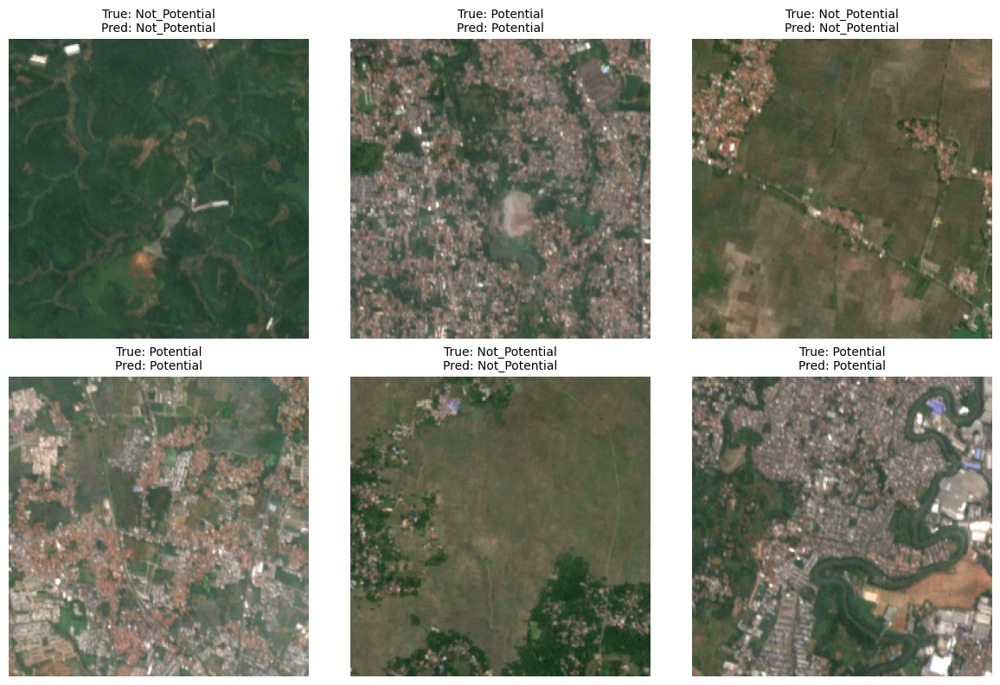

In [ ]:
# Visualisasi hasil prediksi pada data uji
visualize_model(model_ft, phase='test', num_images=6)

## **Menghitung Akurasi pada Data Uji**

In [ ]:
def compute_test_set_accuracy(model, criterion):
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

    test_acc = 0.0
    test_loss = 0.0

    with torch.no_grad():
        model.eval()

        for j, (inputs, labels) in enumerate(dataloaders['test']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = criterion(outputs, labels)
            test_loss += loss.item() * inputs.size(0)

            _, predictions = torch.max(outputs.data, 1)
            correct_counts = predictions.eq(labels.data.view_as(predictions))

            acc = torch.mean(correct_counts.type(torch.FloatTensor))
            test_acc += acc.item() * inputs.size(0)

            print(f"Test Batch number: {j:03d}, Loss: {loss.item():.4f}, Accuracy: {acc.item():.4f}")

    avg_test_loss = test_loss / dataset_sizes['test']
    avg_test_acc = test_acc / dataset_sizes['test']

    print(f"\nTest accuracy: {avg_test_acc:.4f}")


compute_test_set_accuracy(model_ft, criterion)

Test Batch number: 000, Loss: 0.4800, Accuracy: 0.7812
Test Batch number: 001, Loss: 0.2261, Accuracy: 1.0000
Test Batch number: 002, Loss: 0.2311, Accuracy: 0.9688
Test Batch number: 003, Loss: 0.2424, Accuracy: 1.0000
Test Batch number: 004, Loss: 0.2599, Accuracy: 0.9688
Test Batch number: 005, Loss: 0.2931, Accuracy: 0.9688
Test Batch number: 006, Loss: 0.2341, Accuracy: 1.0000
Test Batch number: 007, Loss: 0.2196, Accuracy: 1.0000
Test Batch number: 008, Loss: 0.3068, Accuracy: 0.9062
Test Batch number: 009, Loss: 0.2731, Accuracy: 0.9688
Test Batch number: 010, Loss: 0.3267, Accuracy: 0.9375
Test Batch number: 011, Loss: 0.2832, Accuracy: 0.9375
Test Batch number: 012, Loss: 0.2095, Accuracy: 1.0000
Test Batch number: 013, Loss: 0.5932, Accuracy: 0.7500
Test Batch number: 014, Loss: 1.8106, Accuracy: 0.0000

Test accuracy: 0.9399


## **Melakukan Uji Deteksi pada Data Uji**

In [ ]:
idx_to_class = {v: k for k, v in dataset['train'].class_to_idx.items()}
print(idx_to_class)

{0: 'Not_Potential', 1: 'Potential'}


In [ ]:
def predict(model, test_image_name):
    """Memprediksi kelas dari satu gambar uji"""

    transform = image_transforms['test']

    test_image = Image.open(test_image_name)
    plt.imshow(test_image)
    plt.axis('off')
    plt.show()

    test_image_tensor = transform(test_image)
    test_image_tensor = test_image_tensor.view(1, 3, 224, 224)

    if torch.cuda.is_available():
        test_image_tensor = test_image_tensor.cuda()

    with torch.no_grad():
        model.eval()

        out = model(test_image_tensor)
        ps = F.softmax(out.data, dim=1)

        topk, topclass = ps.topk(2, dim=1)

        for i in range(2):
            predicted_class = idx_to_class[topclass.cpu().numpy()[0][i]]
            score = topk.cpu().numpy()[0][i] * 100
            print(f"Prediction {i+1}: {predicted_class}, Score: {score:.4f}%")

### Potential

Actual       : POTENTIAL


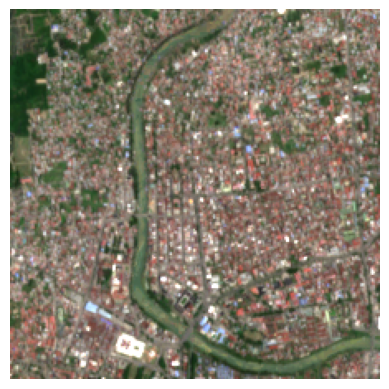

Prediction 1: Potential, Score: 95.5310%
Prediction 2: Not_Potential, Score: 4.4690%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Potential/BandaAceh_r2_c4.png'
print("Actual       : POTENTIAL")
predict(model_ft, test)

Actual       : POTENTIAL


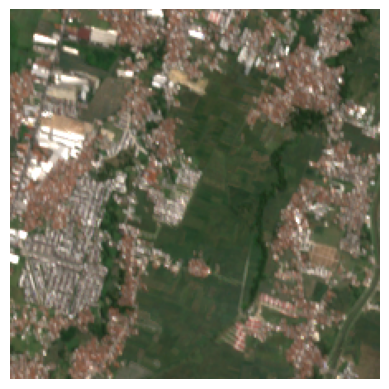

Prediction 1: Potential, Score: 98.5618%
Prediction 2: Not_Potential, Score: 1.4382%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Potential/Bandung_r10_c10.png'
print("Actual       : POTENTIAL")
predict(model_ft, test)

Actual       : POTENTIAL


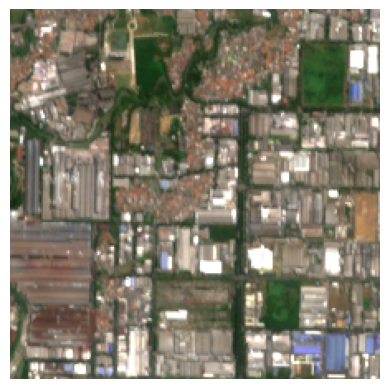

Prediction 1: Potential, Score: 94.3115%
Prediction 2: Not_Potential, Score: 5.6885%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Potential/Jakarta_r10_c36.png'
print("Actual       : POTENTIAL")
predict(model_ft, test)

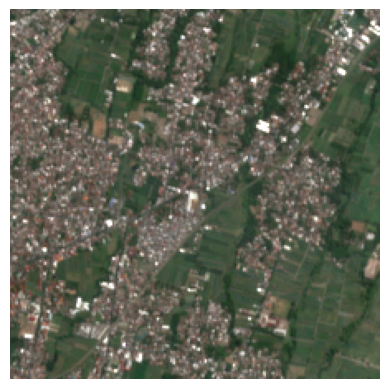

Prediction 1: Potential, Score: 95.9572%
Prediction 2: Not_Potential, Score: 4.0428%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Potential/Kediri_r14_c22.png'
predict(model_ft, test)

Actual       : POTENTIAL


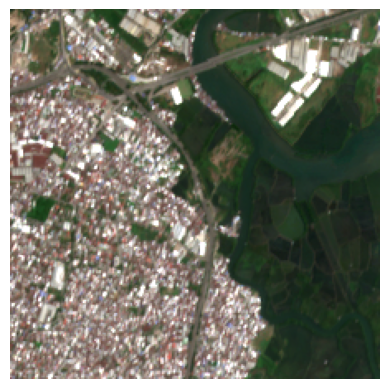

Prediction 1: Potential, Score: 95.3812%
Prediction 2: Not_Potential, Score: 4.6188%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Potential/Makassar_r6_c3.png'
print("Actual       : POTENTIAL")
predict(model_ft, test)

Actual       : POTENTIAL


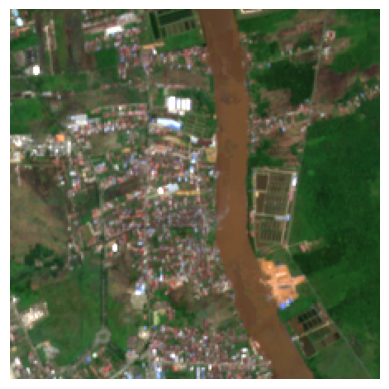

Prediction 1: Potential, Score: 98.2466%
Prediction 2: Not_Potential, Score: 1.7534%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Potential/Pontianak_r8_c9.png'
print("Actual       : POTENTIAL")
predict(model_ft, test)

Actual       : POTENTIAL


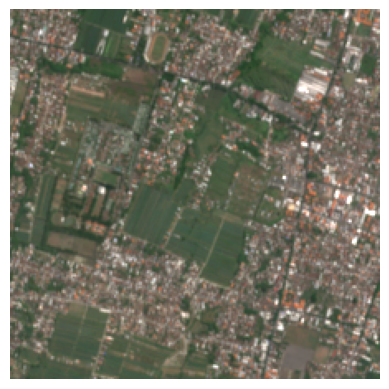

Prediction 1: Potential, Score: 94.6296%
Prediction 2: Not_Potential, Score: 5.3704%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Potential/Surabaya_r15_c10.png'
print("Actual       : POTENTIAL")
predict(model_ft, test)

Actual       : POTENTIAL


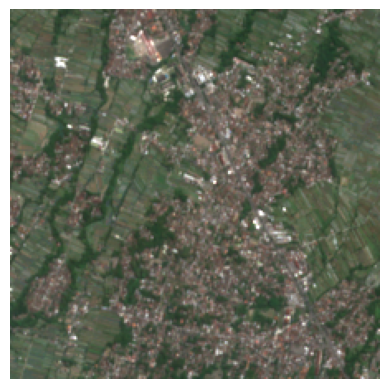

Prediction 1: Potential, Score: 92.1490%
Prediction 2: Not_Potential, Score: 7.8510%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Potential/Yogyakarta_r5_c12.png'
print("Actual       : POTENTIAL")
predict(model_ft, test)

### Not Potential

Actual       : NOT_POTENTIAL


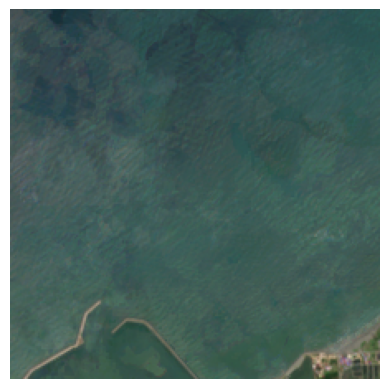

Prediction 1: Not_Potential, Score: 94.7898%
Prediction 2: Potential, Score: 5.2102%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Not_Potential/BandaAceh_r0_c4.png'
print("Actual       : NOT_POTENTIAL")
predict(model_ft, test)

Actual       : NOT_POTENTIAL


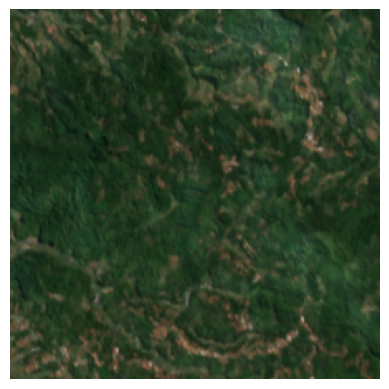

Prediction 1: Not_Potential, Score: 96.1709%
Prediction 2: Potential, Score: 3.8291%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Not_Potential/Bandung_r10_c6.png'
print("Actual       : NOT_POTENTIAL")
predict(model_ft, test)

Actual       : NOT_POTENTIAL


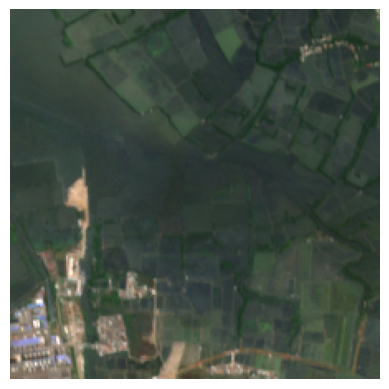

Prediction 1: Not_Potential, Score: 92.6647%
Prediction 2: Potential, Score: 7.3353%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Not_Potential/Jakarta_r0_c30.png'
print("Actual       : NOT_POTENTIAL")
predict(model_ft, test)

Actual       : NOT_POTENTIAL


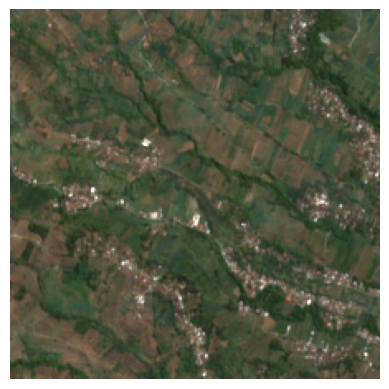

Prediction 1: Not_Potential, Score: 98.7576%
Prediction 2: Potential, Score: 1.2424%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Not_Potential/Kediri_r10_c6.png'
print("Actual       : NOT_POTENTIAL")
predict(model_ft, test)

Actual       : NOT_POTENTIAL


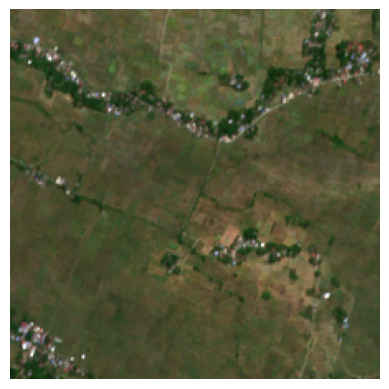

Prediction 1: Not_Potential, Score: 96.1372%
Prediction 2: Potential, Score: 3.8628%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Not_Potential/Makassar_r0_c12.png'
print("Actual       : NOT_POTENTIAL")
predict(model_ft, test)

Actual       : NOT_POTENTIAL


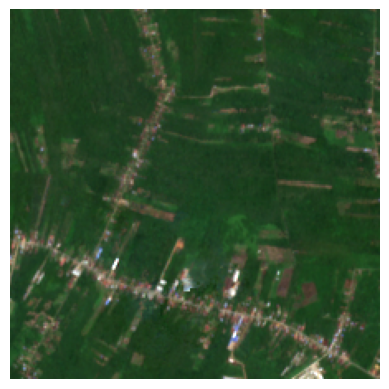

Prediction 1: Not_Potential, Score: 92.9345%
Prediction 2: Potential, Score: 7.0655%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Not_Potential/Pontianak_r3_c12.png'
print("Actual       : NOT_POTENTIAL")
predict(model_ft, test)

Actual       : NOT_POTENTIAL


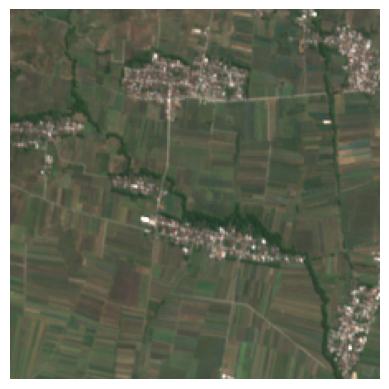

Prediction 1: Not_Potential, Score: 97.8191%
Prediction 2: Potential, Score: 2.1809%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Not_Potential/Surabaya_r9_c0.png'
print("Actual       : NOT_POTENTIAL")
predict(model_ft, test)

Actual       : NOT_POTENTIAL


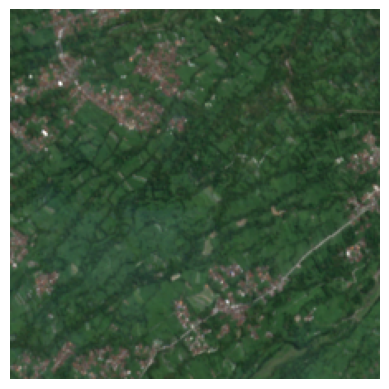

Prediction 1: Not_Potential, Score: 86.9306%
Prediction 2: Potential, Score: 13.0694%


In [ ]:
test = '/content/drive/MyDrive/SolarPanel_Label/Dataset_Split_Final_aug/test/Not_Potential/Yogyakarta_r0_c13.png'
print("Actual       : NOT_POTENTIAL")
predict(model_ft, test)

## **Mengevaluasi Model**

In [ ]:
nb_classes = 2

confusion_matrix = torch.zeros(nb_classes, nb_classes)

with torch.no_grad():
    for i, (inputs, classes_batch) in enumerate(dataloaders['test']):
        inputs = inputs.to(device)
        classes_batch = classes_batch.to(device)
        outputs = model_ft(inputs)
        _, preds = torch.max(outputs, 1)

        for t, p in zip(classes_batch.view(-1), preds.view(-1)):
            confusion_matrix[t.long(), p.long()] += 1

print("Confusion Matrix:\n", confusion_matrix)

Confusion Matrix:
 tensor([[290.,  13.],
        [ 14., 132.]])


In [ ]:
def plot_confusion_matrix(cm, target_names, title='Confusion Matrix', cmap=None, normalize=True):
    accuracy = np.trace(cm) / float(np.sum(cm))
    misclass = 1 - accuracy

    if cmap is None:
        cmap = plt.get_cmap('Blues')

    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()

    if target_names is not None:
        tick_marks = np.arange(len(target_names))
        plt.xticks(tick_marks, target_names, rotation=45)
        plt.yticks(tick_marks, target_names)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    thresh = cm.max() / 1.5 if normalize else cm.max() / 2

    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        if normalize:
            plt.text(j, i, "{:0.4f}".format(cm[i, j]),
                     horizontalalignment="center",
                     color="white" if cm[i, j] > thresh else "black")
        else:
            plt.text(j, i, "{:,}".format(cm[i, j]),
                     horizontalalignment="center",
                     color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label\naccuracy={:0.4f}; misclass={:0.4f}'.format(accuracy, misclass))
    plt.show()

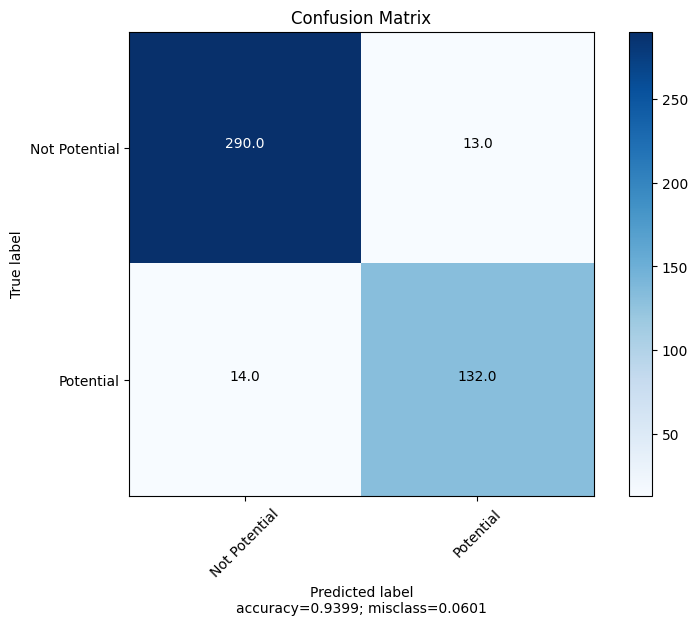

In [ ]:
# Urutan kelas mengikuti ImageFolder (alfabetis): 0 = Not_Potential, 1 = Potential
plot_confusion_matrix(
    cm=confusion_matrix.numpy(),
    normalize=False,
    target_names=['Not Potential', 'Potential'],
    title="Confusion Matrix"
)

In [ ]:
# Mengambil nilai dari Confusion Matrix
# Urutan kelas:
# 0 = Not_Potential
# 1 = Potential
# [[TN, FP],
#  [FN, TP]]

TN = confusion_matrix[0, 0].item()
FP = confusion_matrix[0, 1].item()
FN = confusion_matrix[1, 0].item()
TP = confusion_matrix[1, 1].item()

accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)
recall = TP / (TP + FN)
specificity = TN / (TN + FP)
f1_score = 2 * (precision * recall) / (precision + recall)

print("\n===== HASIL EVALUASI MODEL =====")
print(f"TP          : {TP:.0f}")
print(f"TN          : {TN:.0f}")
print(f"FP          : {FP:.0f}")
print(f"FN          : {FN:.0f}")

print("\n===== PERFORMANCE METRICS =====")
print(f"Accuracy    : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision   : {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall      : {recall:.4f} ({recall * 100:.2f}%)")
print(f"Specificity : {specificity:.4f} ({specificity * 100:.2f}%)")
print(f"F1-Score    : {f1_score:.4f} ({f1_score * 100:.2f}%)")


===== HASIL EVALUASI MODEL =====
TP          : 132
TN          : 290
FP          : 13
FN          : 14

===== PERFORMANCE METRICS =====
Accuracy    : 0.9399 (93.99%)
Precision   : 0.9103 (91.03%)
Recall      : 0.9041 (90.41%)
Specificity : 0.9571 (95.71%)
F1-Score    : 0.9072 (90.72%)
